In [ ]:
!pip install torch torchvision matplotlib numpy scipy six torchaudio 
#!pip install umap-learn torc

from __future__ import print_function
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import savgol_filter
from six.moves import xrange

#import umap

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torch.optim as optim

import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torchvision.utils import make_grid

import os
import torchaudio
import torchaudio.transforms as T
from torch.utils.data import Dataset, DataLoader

In [6]:
def collate_fn(batch):    
    batch = [item for item in batch if item is not None]    
    return torch.utils.data.dataloader.default_collate(batch)

class GTZANDataset(Dataset):    
    def __init__(self, root_dir, transform=None, target_length=None, target_time_steps=None): 
        self.root_dir = root_dir      
        self.transform = transform      
        self.target_length = target_length      
        self.target_time_steps = target_time_steps       
        self.file_paths = []       
        self.labels = []   
        
        genres = os.listdir(root_dir)       
        for label, genre in enumerate(genres):           
            genre_path = os.path.join(root_dir, genre)          
            if os.path.isdir(genre_path):               
                for filename in os.listdir(genre_path):                    
                    if filename.endswith(".wav"):                       
                        self.file_paths.append(os.path.join(genre_path, filename))    
                        self.labels.append(label)    
                        
    def __len__(self):       
        return len(self.file_paths)    
    
    def __getitem__(self, idx):              
        file_path = self.file_paths[idx]        
        try:                       
            waveform, sample_rate = torchaudio.load(file_path)                       
            if self.target_length is not None:                
                waveform = self._pad_or_trim(waveform, self.target_length)                    
            
            if self.transform:                
                mel_spec = self.transform(waveform)                                          
                if self.target_time_steps is not None:                   
                    mel_spec = self._pad_or_trim_mel(mel_spec, self.target_time_steps) 
            
            label = self.labels[idx]            
            return mel_spec, label           
        except Exception as e:                
            return None    
    
    def _pad_or_trim(self, waveform, target_length):        
        current_length = waveform.shape[1]        
        if current_length > target_length:            
            waveform = waveform[:, :target_length]        
        elif current_length < target_length:            
            padding = target_length - current_length            
            waveform = torch.nn.functional.pad(waveform, (0, padding))        
        return waveform    
    
    def _pad_or_trim_mel(self, mel_spec, target_time_steps):              
        current_length = mel_spec.shape[-1]        
        if current_length > target_time_steps:            
            mel_spec = mel_spec[:, :, :target_time_steps]        
        elif current_length < target_time_steps:            
            padding = target_time_steps - current_length            
            mel_spec = torch.nn.functional.pad(mel_spec, (0, padding))        
        return mel_spec

160 40
Waveforms shape: torch.Size([32, 1, 128, 1600])
Labels: tensor([6, 0, 5, 5, 1, 5, 4, 7, 2, 2, 6, 2, 4, 0, 6, 8, 6, 7, 7, 4, 0, 2, 0, 5,
        3, 6, 7, 1, 9, 0, 1, 1])
Max value in Mel-Spectrogram: tensor(152511.4375)
Min value in Mel-Spectrogram: tensor(0.)
Mean value in Mel-Spectrogram: tensor(116.8777)


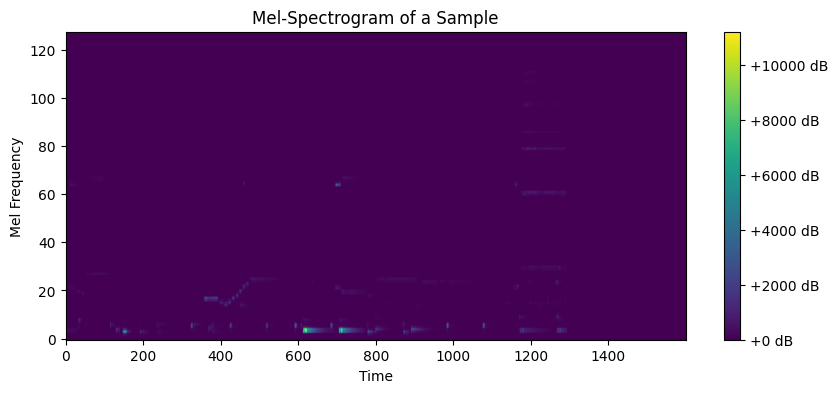

In [7]:
from torch.utils.data import random_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
transform = T.MelSpectrogram(sample_rate=22050, n_fft=2048, hop_length=512, n_mels=128)

root_dir = "/kaggle/input/gtzandatabase/GTZAN_TEST/genres_original/"  # 确保这里填入正确的路径

target_time_steps = 1600
full_data = GTZANDataset(root_dir=root_dir, transform=transform, target_time_steps=target_time_steps)

train_size = int(0.8 * len(full_data))
val_size = len(full_data) - train_size
print(train_size, val_size)

train_data, val_data = random_split(full_data, [train_size, val_size])
train_loader = DataLoader(train_data, batch_size=32, shuffle=True,collate_fn=collate_fn)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False,collate_fn=collate_fn)

for batch in train_loader:    
    waveforms, labels = batch    
    print("Waveforms shape:", waveforms.shape)     
    print("Labels:", labels)           
    
    print("Max value in Mel-Spectrogram:", torch.max(waveforms))   
    print("Min value in Mel-Spectrogram:", torch.min(waveforms))   
    print("Mean value in Mel-Spectrogram:", torch.mean(waveforms))       
    
    if torch.all(waveforms == 0):        
        print("Warning: Mel-Spectrogram contains only zeros!")        
    
    # 可视化某些梅尔频谱图    
    import matplotlib.pyplot as plt    
    import numpy as np       
    mel_spec = waveforms[0].cpu().numpy()      
    plt.figure(figsize=(10, 4))    
    plt.imshow(mel_spec[0], aspect="auto", origin="lower")   
    plt.title("Mel-Spectrogram of a Sample")   
    plt.xlabel("Time")    
    plt.ylabel("Mel Frequency")  
    plt.colorbar(format="%+2.0f dB")    
    plt.show()    
    break  

In [8]:
class VectorQuantizer(nn.Module):    
    def __init__(self, num_embeddings, embedding_dim, commitment_cost):        
        super(VectorQuantizer, self).__init__()    
        
        self._embedding_dim = embedding_dim        
        self._num_embeddings = num_embeddings                
        self._embedding = nn.Embedding(self._num_embeddings, self._embedding_dim)        
        self._embedding.weight.data.uniform_(-1/self._num_embeddings, 1/self._num_embeddings)       
        self._commitment_cost = commitment_cost    
    
    def forward(self, inputs):              
        inputs = inputs.permute(0, 2, 3, 1).contiguous()       
        input_shape = inputs.shape                     
        flat_input = inputs.view(-1, self._embedding_dim)                      
        distances = (torch.sum(flat_input**2, dim=1, keepdim=True)                    
                     + torch.sum(self._embedding.weight**2, dim=1)                   
                     - 2 * torch.matmul(flat_input, self._embedding.weight.t()))   
        encoding_indices = torch.argmin(distances, dim=1).unsqueeze(1)       
        encodings = torch.zeros(encoding_indices.shape[0], self._num_embeddings, device=inputs.device)
        encodings.scatter_(1, encoding_indices, 1)                       
        quantized = torch.matmul(encodings, self._embedding.weight).view(input_shape)               
        
        # Loss       
        e_latent_loss = F.mse_loss(quantized.detach(), inputs)        
        q_latent_loss = F.mse_loss(quantized, inputs.detach())        
        loss = q_latent_loss + self._commitment_cost * e_latent_loss                
        quantized = inputs + (quantized - inputs).detach()        
        avg_probs = torch.mean(encodings, dim=0)        
        perplexity = torch.exp(-torch.sum(avg_probs * torch.log(avg_probs + 1e-10)))      
        
        #BHWC -> BCHW        
        return loss, quantized.permute(0, 3, 1, 2).contiguous(), perplexity, encodings

In [9]:
class VectorQuantizerEMA(nn.Module):    
    def __init__(self, num_embeddings, embedding_dim, commitment_cost, decay, epsilon=1e-5):        
        super(VectorQuantizerEMA, self).__init__()     
        
        self._embedding_dim = embedding_dim       
        self._num_embeddings = num_embeddings               
        self._embedding = nn.Embedding(self._num_embeddings, self._embedding_dim)       
        self._embedding.weight.data.normal_()     
        self._commitment_cost = commitment_cost           
        self.register_buffer('_ema_cluster_size', torch.zeros(num_embeddings))     
        self._ema_w = nn.Parameter(torch.Tensor(num_embeddings, self._embedding_dim))      
        self._ema_w.data.normal_()              
        self._decay = decay        
        self._epsilon = epsilon    
        
    def forward(self, inputs):             
        inputs = inputs.permute(0, 2, 3, 1).contiguous()     
        input_shape = inputs.shape                  
        
        flat_input = inputs.view(-1, self._embedding_dim)                    
        
        distances = (torch.sum(flat_input**2, dim=1, keepdim=True)           
                     + torch.sum(self._embedding.weight**2, dim=1)          
                     - 2 * torch.matmul(flat_input, self._embedding.weight.t()))   
        
        encoding_indices = torch.argmin(distances, dim=1).unsqueeze(1)     
        encodings = torch.zeros(encoding_indices.shape[0], self._num_embeddings, device=inputs.device)
        encodings.scatter_(1, encoding_indices, 1)                     
        quantized = torch.matmul(encodings, self._embedding.weight).view(input_shape)   
        
        if self.training:           
            self._ema_cluster_size = self._ema_cluster_size * self._decay + \
                                        (1 - self._decay) * torch.sum(encodings, 0)        
            n = torch.sum(self._ema_cluster_size.data)           
            self._ema_cluster_size = (               
                (self._ema_cluster_size + self._epsilon)               
                / (n + self._num_embeddings * self._epsilon) * n)                   
            
            dw = torch.matmul(encodings.t(), flat_input)          
            self._ema_w = nn.Parameter(self._ema_w * self._decay + (1 - self._decay) * dw)   
            
            self._embedding.weight = nn.Parameter(self._ema_w / self._ema_cluster_size.unsqueeze(1)) 
       
        # Loss        
        e_latent_loss = F.mse_loss(quantized.detach(), inputs)       
        loss = self._commitment_cost * e_latent_loss                     
        
        quantized = inputs + (quantized - inputs).detach()       
        avg_probs = torch.mean(encodings, dim=0)      
        perplexity = torch.exp(-torch.sum(avg_probs * torch.log(avg_probs + 1e-10)))    
        
        return loss, quantized.permute(0, 3, 1, 2).contiguous(), perplexity, encodings

In [10]:
class Residual(nn.Module):    
    def __init__(self, in_channels, num_hiddens, num_residual_hiddens):        
        super(Residual, self).__init__()        
        self._block = nn.Sequential(           
            nn.ReLU(True),            
            nn.Conv2d(in_channels=in_channels,                     
                      out_channels=num_residual_hiddens,                     
                      kernel_size=3, stride=1, padding=1, bias=False),            
            nn.ReLU(True),           
            nn.Conv2d(in_channels=num_residual_hiddens,                  
                      out_channels=num_hiddens,                   
                      kernel_size=1, stride=1, bias=False)        
        )
    
    def forward(self, x):        
        return x + self._block(x)
    
class ResidualStack(nn.Module):    
    def __init__(self, in_channels, num_hiddens, num_residual_layers, num_residual_hiddens):    
        super(ResidualStack, self).__init__()       
        self._num_residual_layers = num_residual_layers       
        self._layers = nn.ModuleList([Residual(in_channels, num_hiddens, num_residual_hiddens)   
                                      for _ in range(self._num_residual_layers)])   
    
    def forward(self, x):        
        for i in range(self._num_residual_layers):            
            x = self._layers[i](x)        
        return F.relu(x)

In [11]:
class Encoder(nn.Module):    
    def __init__(self, in_channels, num_hiddens, num_residual_layers, num_residual_hiddens):    
        super(Encoder, self).__init__()        
        
        self._conv_1 = nn.Conv2d(in_channels=in_channels,              
                                 out_channels=num_hiddens//2,             
                                 kernel_size=4,                            
                                 stride=2, padding=1)       
        self._conv_2 = nn.Conv2d(in_channels=num_hiddens//2,           
                                 out_channels=num_hiddens,          
                                 kernel_size=4,                   
                                 stride=2, padding=1)       
        self._conv_3 = nn.Conv2d(in_channels=num_hiddens,       
                                 out_channels=num_hiddens,       
                                 kernel_size=3,                
                                 stride=1, padding=1)       
        self._residual_stack = ResidualStack(in_channels=num_hiddens,    
                                             num_hiddens=num_hiddens,       
                                             num_residual_layers=num_residual_layers,   
                                             num_residual_hiddens=num_residual_hiddens)  
    
    def forward(self, inputs):       
        x = self._conv_1(inputs)      
        x = F.relu(x)              
        x = self._conv_2(x)       
        x = F.relu(x)            
        x = self._conv_3(x)        
        return self._residual_stack(x)

class Decoder(nn.Module):   
    def __init__(self, in_channels, num_hiddens, num_residual_layers, num_residual_hiddens):   
        super(Decoder, self).__init__()               
        self._conv_1 = nn.Conv2d(in_channels=in_channels,      
                                 out_channels=num_hiddens,     
                                 kernel_size=3,             
                                 stride=1, padding=1)           
        self._residual_stack = ResidualStack(in_channels=num_hiddens,    
                                             num_hiddens=num_hiddens,  
                                             num_residual_layers=num_residual_layers,  
                                             num_residual_hiddens=num_residual_hiddens)      
        self._conv_trans_1 = nn.ConvTranspose2d(in_channels=num_hiddens,    
                                                out_channels=num_hiddens//2,   
                                                kernel_size=4,                
                                                stride=2, padding=1)         
        self._conv_trans_2 = nn.ConvTranspose2d(in_channels=num_hiddens//2,     
                                                out_channels=1,   
                                                kernel_size=4,     
                                                stride=2, padding=1)  
    
    def forward(self, inputs):       
        x = self._conv_1(inputs)          
        x = self._residual_stack(x)             
        x = self._conv_trans_1(x)     
        x = F.relu(x)              
        return self._conv_trans_2(x)

In [12]:
batch_size = 32
num_training_updates = 820

num_hiddens = 128
num_residual_hiddens = 32
num_residual_layers = 2

embedding_dim = 64
num_embeddings = 512

commitment_cost = 0.25

decay = 0.99

learning_rate = 1e-3

In [13]:
class DiffusionModel(nn.Module):    
    def __init__(self, embedding_dim, num_hiddens, num_residual_layers, num_residual_hiddens, attention_dim=64, lstm_hidden_dim=32):       
        super(DiffusionModel, self).__init__()        
        
        self.lstm = nn.LSTM(input_size=1600, hidden_size=lstm_hidden_dim, num_layers=1, batch_first=True)   
        self.attention_fc = nn.Linear(lstm_hidden_dim, attention_dim)       
        
        self.encoder = nn.Sequential(            
            nn.Conv2d(embedding_dim, num_hiddens, kernel_size=3, stride=2, padding=1),          
            nn.ReLU(),            
            *[ResidualBlock(num_hiddens) for _ in range(num_residual_layers)]        
        )              
        
        self.bottleneck = nn.Conv2d(num_hiddens, num_hiddens, kernel_size=3, stride=1, padding=1)       
        self.decoder = nn.Sequential(            
            *[ResidualBlock(num_hiddens) for _ in range(num_residual_layers)],        
            nn.ConvTranspose2d(num_hiddens, embedding_dim, kernel_size=3, stride=2, padding=1, output_padding=1)   
        )   
    
    def forward(self, noisy_latent, original_latent, x):               
        batch_size, _, height, width = x.size()  # (32, 1, 128, 1600)       
        x_reshaped = x.view(batch_size, height, width)                
        
        lstm_out, (h_n, c_n) = self.lstm(x_reshaped)                 
        
        lstm_last_step = lstm_out[:, -1, :]               
        
        attention_features = self.attention_fc(lstm_last_step)         
        attention_features = attention_features.to(noisy_latent.device)               
        
        batch_size, attention_channels = attention_features.shape        
        attention_expanded = attention_features.view(batch_size, attention_channels, 1, 1)     
        attention_expanded = attention_expanded.expand(-1, -1, noisy_latent.size(2), noisy_latent.size(3))     
        attention_expanded = attention_expanded.to(noisy_latent.device)               
        
        modified_latent = noisy_latent *  attention_expanded       
        
        encoded = self.encoder(modified_latent)          
        bottleneck_out = self.bottleneck(encoded)          
        denoised_latent = self.decoder(bottleneck_out)       
        consistency_loss = F.mse_loss(denoised_latent, original_latent)    
        
        return denoised_latent, consistency_loss
    
class ResidualBlock(nn.Module):    
    def __init__(self, num_hiddens):       
        super(ResidualBlock, self).__init__()       
        self.conv1 = nn.Conv2d(num_hiddens, num_hiddens, kernel_size=3, stride=1, padding=1)    
        self.conv2 = nn.Conv2d(num_hiddens, num_hiddens, kernel_size=3, stride=1, padding=1)   
        
    def forward(self, x):       
        residual = x        
        x = F.relu(self.conv1(x))      
        x = self.conv2(x)      
        return F.relu(x + residual)

class Model(nn.Module):   
    def __init__(self, num_hiddens, num_residual_layers, num_residual_hiddens,               
                 num_embeddings, embedding_dim, commitment_cost, decay=0):       
        super(Model, self).__init__()                
        
        self._encoder = Encoder(1, num_hiddens,                            
                                num_residual_layers,                     
                                num_residual_hiddens)               
        self._pre_vq_conv = nn.Conv2d(in_channels=num_hiddens,          
                                      out_channels=embedding_dim,     
                                      kernel_size=1,               
                                      stride=1)               
        if decay > 0.0:           
            self._vq_vae = VectorQuantizerEMA(num_embeddings, embedding_dim,     
                                              commitment_cost, decay)       
        else:            
            self._vq_vae = VectorQuantizer(num_embeddings, embedding_dim,        
                                               commitment_cost)           
        self._decoder = Decoder(embedding_dim,                   
                                num_hiddens,                   
                                num_residual_layers,          
                                num_residual_hiddens)               
        self.diffusion_model = DiffusionModel(embedding_dim, num_hiddens, num_residual_layers, num_residual_hiddens)       
        
    def forward(self, x):            
        z = self._encoder(x)     
        z = self._pre_vq_conv(z)       
        
        vq_loss, quantized, perplexity, _ = self._vq_vae(z)      
        
        noisy_latent = self._inject_noise(quantized)     
        batch_size, _, _, _ = noisy_latent.size()       
        denoised_latent, consistency_loss = self.diffusion_model(noisy_latent, quantized, x)      
        
        x_recon = self._decoder(denoised_latent)      
        
        return vq_loss, x_recon, perplexity, consistency_loss      
    
    def _inject_noise(self, latent, noise_level=0.001):      
        noise = torch.randn_like(latent) * noise_level    
        return latent + noise

In [14]:
model = Model(num_hiddens, num_residual_layers, num_residual_hiddens,            
              num_embeddings, embedding_dim,               
              commitment_cost, decay).to(device)

In [15]:
optimizer = optim.Adam(model.parameters(), lr=learning_rate, amsgrad=False)

In [ ]:
model.train()
train_res_recon_error = []
train_res_perplexity = []
train_res_consistency_loss = [] 

train_iter = iter(train_loader)
for i in xrange(num_training_updates):    
    # (data, _) = next(iter(train_loader))    
    try:
        data, _ = next(train_iter)  # 每次取下一个批次
    except StopIteration:
        train_iter = iter(train_loader)
        
    data = data.to(device)    
    optimizer.zero_grad()    
    
    vq_loss, data_recon, perplexity, consistency_loss = model(data)    
    recon_error = F.mse_loss(data_recon, data)    
    loss = recon_error + vq_loss + consistency_loss   
    loss.backward()   
    
    optimizer.step()        
    
    train_res_recon_error.append(recon_error.item())   
    train_res_perplexity.append(perplexity.item())    
    train_res_consistency_loss.append(consistency_loss.item())  
    
    if (i+1) % 20 == 0:      
        print('%d iterations' % (i+1))     
        print('recon_error: %.3f' % np.mean(train_res_recon_error[-100:]))      
        print('perplexity: %.3f' % np.mean(train_res_perplexity[-100:]))      
        print()

60 iterations
recon_error: 896520.877
perplexity: 6.754

80 iterations
recon_error: 868125.772
perplexity: 7.093



Text(0.5, 0, 'iteration')

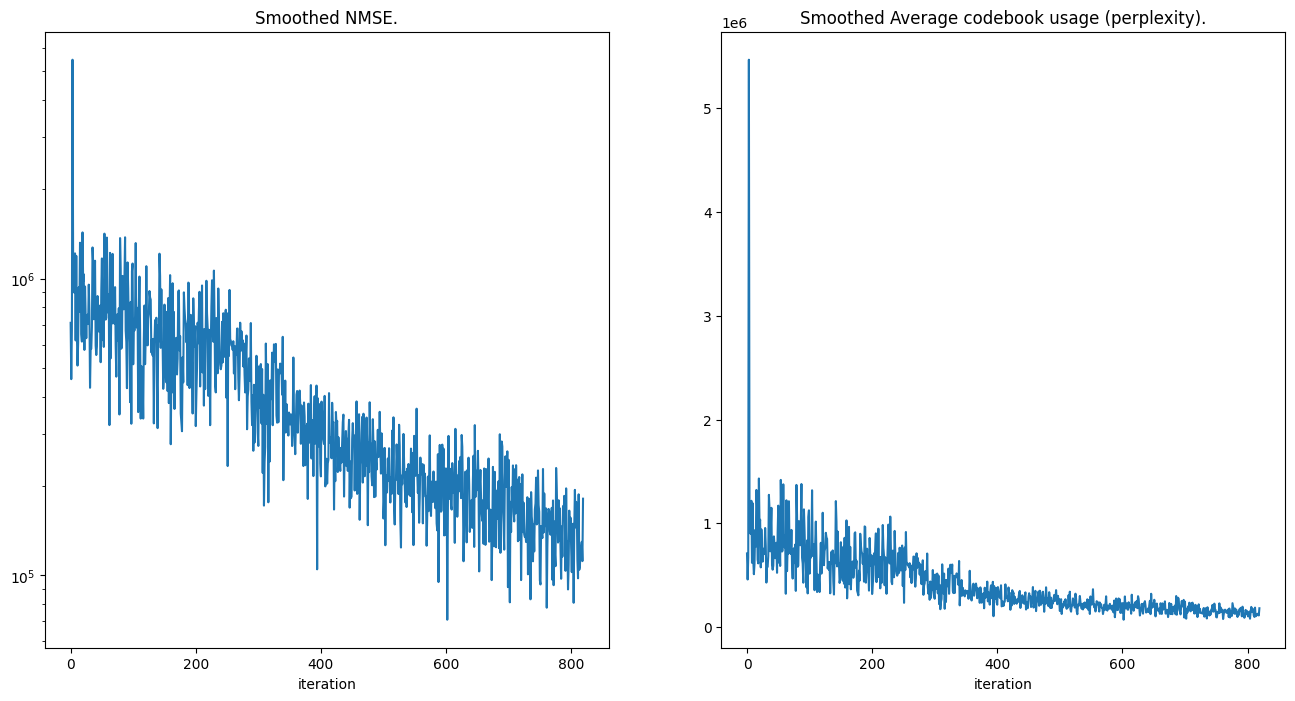

In [14]:
f = plt.figure(figsize=(16,8))
ax = f.add_subplot(1,2,1)
ax.plot(train_res_recon_error)
ax.set_yscale('log')
ax.set_title('Smoothed NMSE.')
ax.set_xlabel('iteration')

ax = f.add_subplot(1,2,2)
ax.plot(train_res_recon_error)
ax.set_title('Smoothed Average codebook usage (perplexity).')
ax.set_xlabel('iteration')

In [15]:
def inject_noise(latent, noise_level=0.001):      
    noise = torch.randn_like(latent) * noise_level    
    return latent + noise
    
model.eval()

(valid_originals, _) = next(iter(val_loader))
valid_originals = valid_originals.to(device)

vq_output_eval = model._pre_vq_conv(model._encoder(valid_originals))
_, valid_quantize, _, _ = model._vq_vae(vq_output_eval)

#valid_reconstructions = model._decoder(valid_quantize)

noisy_latent = inject_noise(valid_quantize)       
denoised_latent, consistency_loss = model.diffusion_model(noisy_latent, valid_quantize, valid_originals)
valid_reconstructions = model._decoder(denoised_latent)


In [16]:
(train_originals, _) = next(iter(train_loader))
train_originals = train_originals.to(device)
_, train_reconstructions, _, _ = model._vq_vae(train_originals)

In [17]:
def show(img):    
    npimg = img.numpy()   
    fig = plt.imshow(np.transpose(npimg, (1,2,0)), interpolation='nearest')  
    fig.axes.get_xaxis().set_visible(False)   
    fig.axes.get_yaxis().set_visible(False)

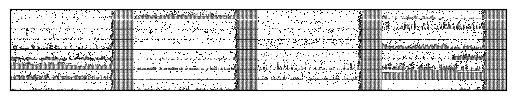

In [18]:
show(make_grid(valid_reconstructions.cpu().data, nrow=4), )

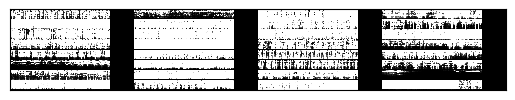

In [19]:
show(make_grid(valid_originals.cpu(), nrow=4))

In [20]:
proj = umap.UMAP(n_neighbors=3,    
                 min_dist=0.1,          
                 metric='cosine').fit_transform(model._vq_vae._embedding.weight.data.cpu())

NameError: name 'umap' is not defined

In [21]:
plt.scatter(proj[:,0], proj[:,1], alpha=0.3)

NameError: name 'proj' is not defined

In [23]:
import scipy.ndimage

mel_spec = valid_reconstructions[2, 0]
mel_spec2 = valid_originals[2, 0]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# 假设 mel_spec 是一个包含梅尔谱图的 Tensor
print("Max value in Mel-Spectrogram:", torch.max(mel_spec2).item())
print("Min value in Mel-Spectrogram:", torch.min(mel_spec2).item())
print("Mean value in Mel-Spectrogram:", torch.mean(mel_spec2).item())

# 检查是否有全零的情况
if torch.all(mel_spec2 == 0):    
    print("Warning: Mel-Spectrogram contains only zeros!")
else:    
    print("Mel-Spectrogram looks non-zero.")
    
# 假设 mel_spec 已经定义
mel_spec = mel_spec.to(device)
mel_spec2 = mel_spec2.to(device)

mel_spec_smoothed = scipy.ndimage.gaussian_filter(mel_spec.detach().cpu().numpy(), sigma=1.0)
mel_spec2_smoothed = scipy.ndimage.gaussian_filter(mel_spec2.detach().cpu().numpy(), sigma=1.0)

# 将平滑后的数据转换回 Tensor 并移动到原设备
mel_spec_smoothed = torch.from_numpy(mel_spec_smoothed).to(device)
mel_spec2_smoothed = torch.from_numpy(mel_spec2_smoothed).to(device)

# 定义 mel_to_spec 并确保在相同设备上
n_fft = 2048
n_mels = 128
sample_rate = 22050

mel_to_spec = T.InverseMelScale(n_stft=n_fft // 2 + 1, n_mels=n_mels, sample_rate=sample_rate).to(device)

# 进行转换
linear_spec = mel_to_spec(mel_spec)
linear_spec2 = mel_to_spec(mel_spec2)
linear_spec = linear_spec.to("cpu")
linear_spec2 = linear_spec2.to("cpu")

# 重新定义 GriffinLim，并确保 window 也在 CPU 上
istft = T.GriffinLim(n_fft=n_fft, hop_length=512, n_iter=160)

# 运行 GriffinLim 逆变换
waveform = istft(linear_spec)
orgin = istft(linear_spec2)
output_file = "reconstructed_audio3.wav"
torchaudio.save(output_file, waveform.unsqueeze(0), sample_rate)
output_file2 = "orgin3.wav"
torchaudio.save(output_file2, orgin.unsqueeze(0), sample_rate) 

Max value in Mel-Spectrogram: 86406.296875
Min value in Mel-Spectrogram: 0.0
Mean value in Mel-Spectrogram: 253.50128173828125
Mel-Spectrogram looks non-zero.
